In [434]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.viz.SessionVisualizer import SessionVisualizer
from src.viz.CellVisualizer import CellVisualizer
from src.analysis.CellAnalysis import CellAnalyzer, SessionAnalyzer
from src.decoding.Decoders import MLE, MLEDistance, RidgeDistance
from src.decoding.NNDecoder import NNDecoder

import numpy as np
import matplotlib.pyplot as plt
from src.workflows import load_dataframe

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM040'
record_date = '251130'
experiment_name = 'tiling_2_120um'

device = RadialDevice(mouse_name=mouse_name, record_date=record_date, experiment_name=experiment_name)
session_df = load_dataframe(mouse_name=mouse_name, record_date=record_date, experiment_name=experiment_name)

session_name = f"{record_date}_{mouse_name}_{experiment_name}"
if 'session_name' not in session_df.columns:
   for i, row in session_df.iterrows():
      session_df.loc[i, 'session_name'] = session_name

viz = SessionVisualizer(session_df, animal_id=mouse_name, experiment_name=experiment_name)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[ok] Loading session: 251130_SAM040_tiling_2_120um
Directory results already exists
Successfully loaded activity data
Stimulus file found
Repeat stimulus on length distribution:
    96 repeats have length 61
    24 repeats have length 62
Set stimulus on length: 61
[ok] Loaded DataFrame from D:/data-distance-coding-project/processed-data\251130_SAM040_tiling_2_120um\251130_SAM040_tiling_2_120um_dataframe.pkl (1894 cells)


=== Fold 10/10 ===
Total predictions: 2928
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          0.786
    RMSE:         1.124
    Bias:         0.035
    Correlation:  0.468

  ANGLE:
    MAE:          6.68
    RMSE:         8.58
    R²:           0.894
    Correlation:  0.952

  Reference (random distance MAE ~ 1.25)


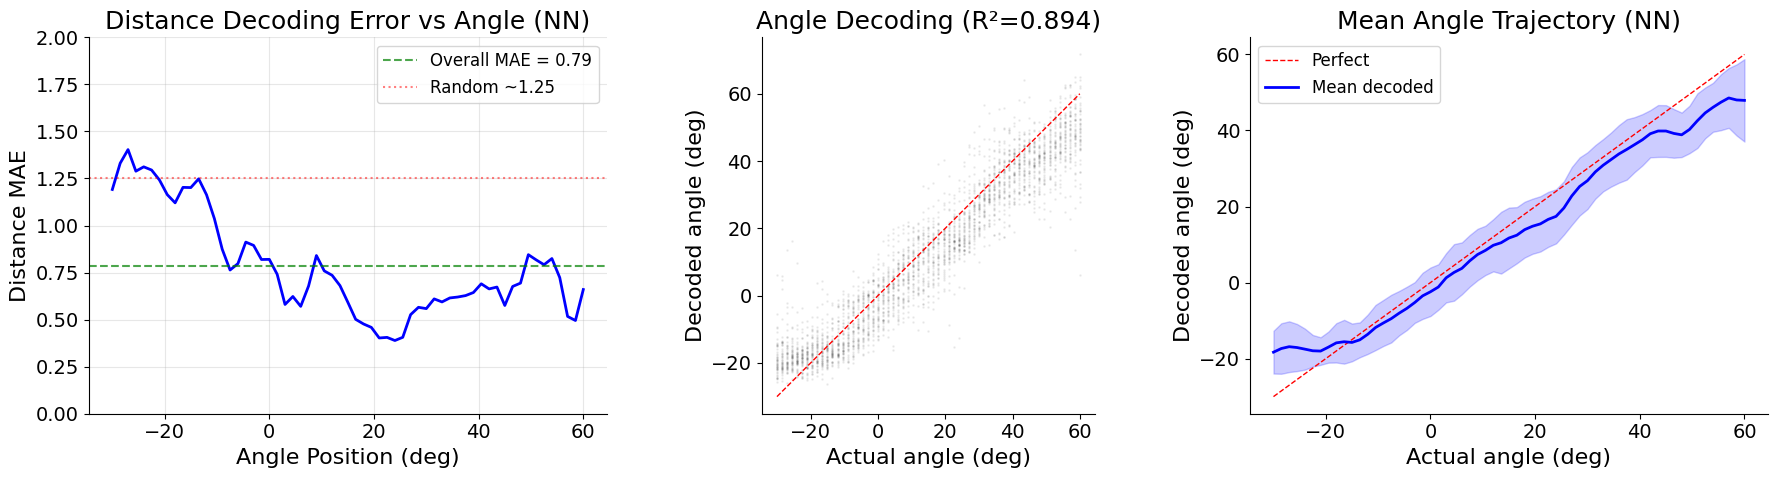

In [441]:
binocular_decoder = NNDecoder(device, cells_to_include, monocular=0)
results_binocular = binocular_decoder.cross_validate(k_folds=10)
fig = binocular_decoder.plot_results(results_binocular)

=== Fold 10/10 ===
Total predictions: 2928
NN DECODER PERFORMANCE
  DISTANCE:
    MAE:          1.090
    RMSE:         1.358
    Bias:         0.015
    Correlation:  0.185

  ANGLE:
    MAE:          7.93
    RMSE:         10.30
    R²:           0.848
    Correlation:  0.928

  Reference (random distance MAE ~ 1.25)


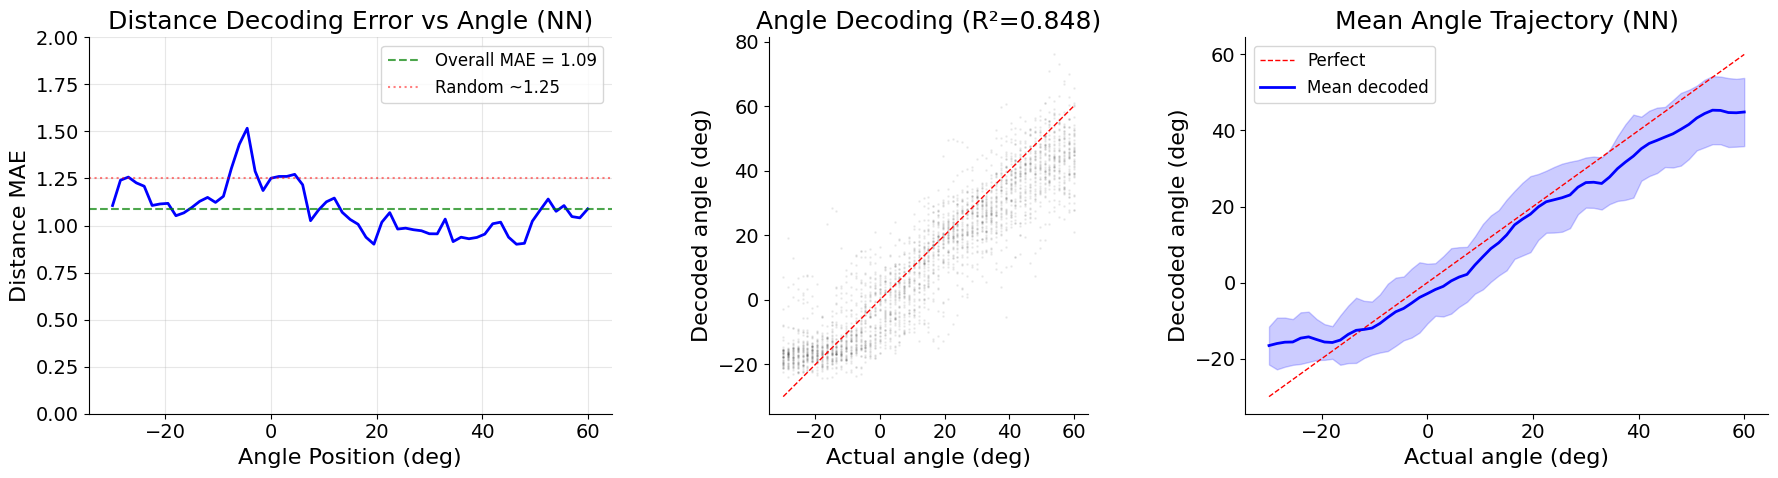

In [443]:
monocular_decoder = NNDecoder(device, cells_to_include, monocular=1)
results_monocular = monocular_decoder.cross_validate(k_folds=10)
fig = monocular_decoder.plot_results(results_monocular)

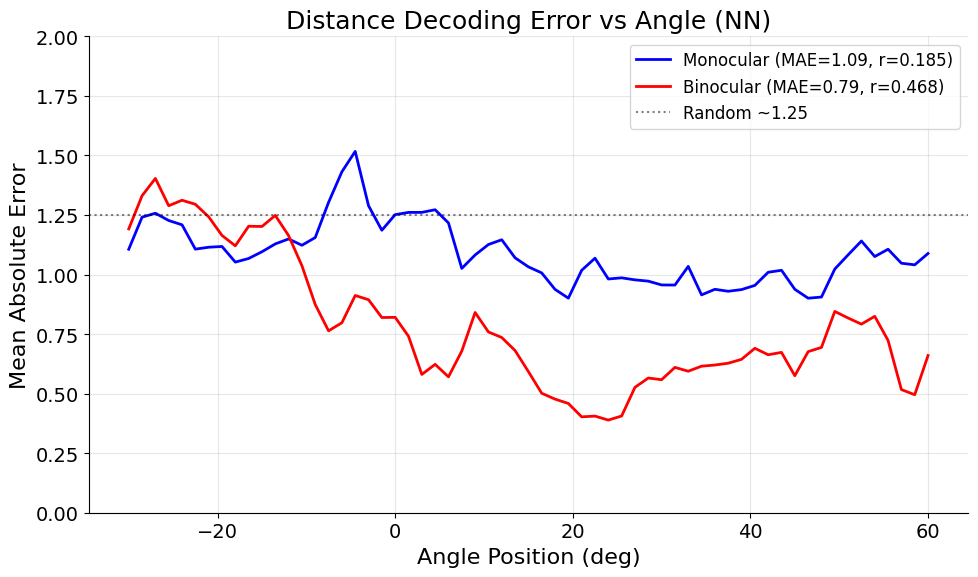

: 

In [ ]:
fig = decoder.plot_results_comparison([results_monocular, results_binocular], ['Monocular', 'Binocular'])

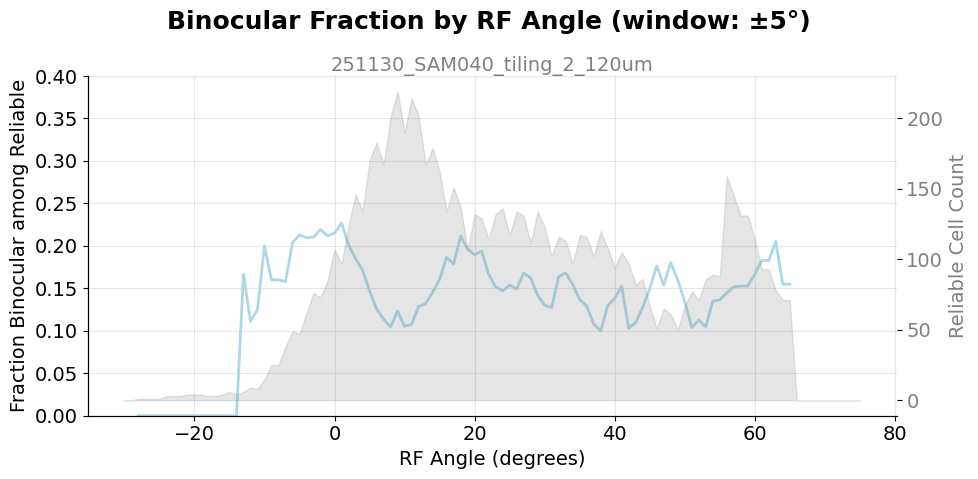

In [409]:
fig = viz.plot_modulation_fraction_by_angle()

In [411]:
cells_to_include = viz.filter_by_reliability(session_df, reliable_type='reliable', threshold=0.85)['cell_id'].values
print('Using {} cells'.format(len(cells_to_include)))

Using 846 cells


In [412]:
binocular_decoder = MLE(device, cells_to_include, monocular=False)
results = binocular_decoder.cross_validate()

monocular_decoder = MLE(device, cells_to_include, monocular=True)
monocular_results = monocular_decoder.cross_validate()


Trial 48/48
Total test trials: 48
  MAE:          3.91
  RMSE:         5.54
  Correlation:  0.978
  R²:           0.956
Trial 48/48
Total test trials: 48
  MAE:          4.77
  RMSE:         7.51
  Correlation:  0.960
  R²:           0.919


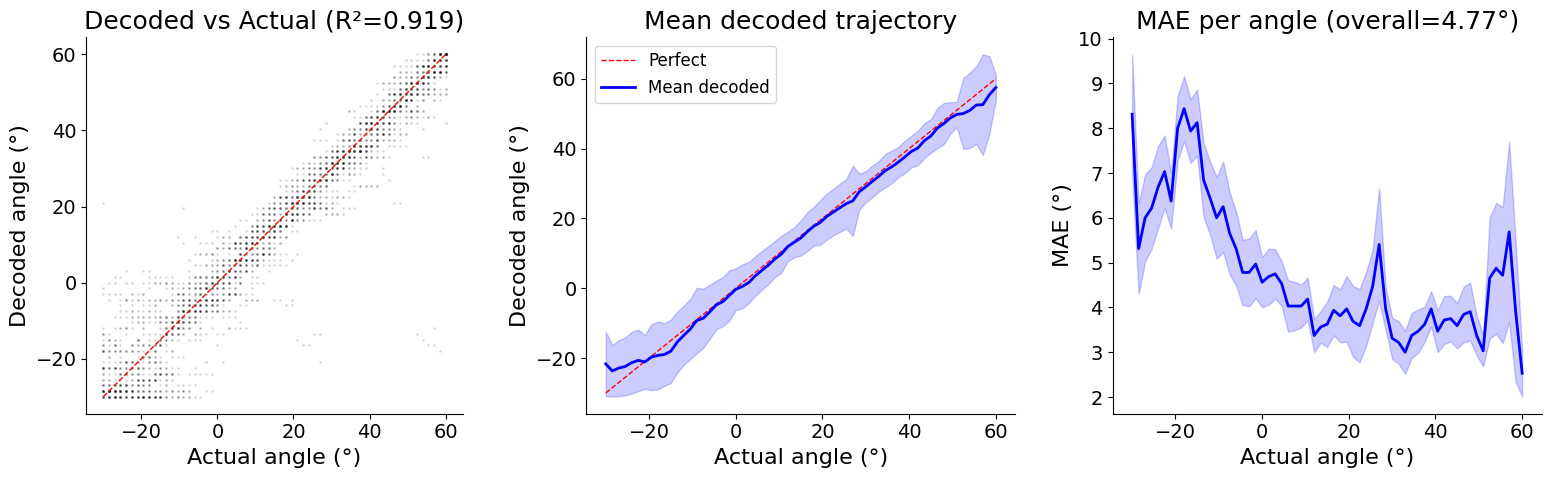

In [413]:
monocular_decoder.plot_results(monocular_results)

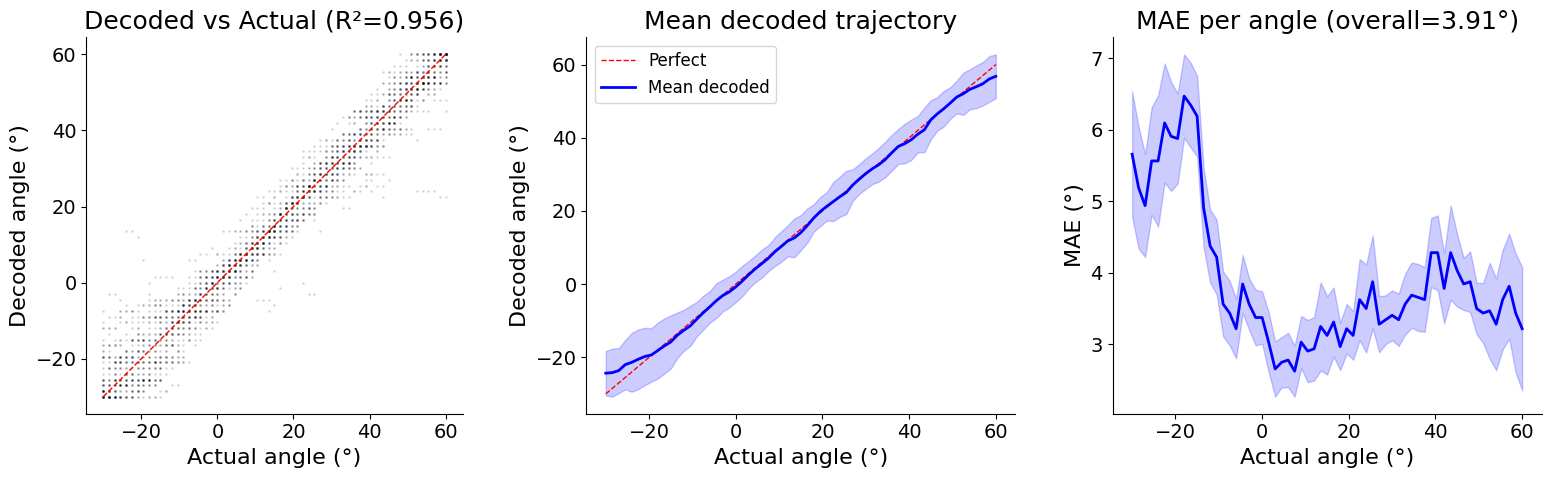

In [414]:
binocular_decoder.plot_results(results)

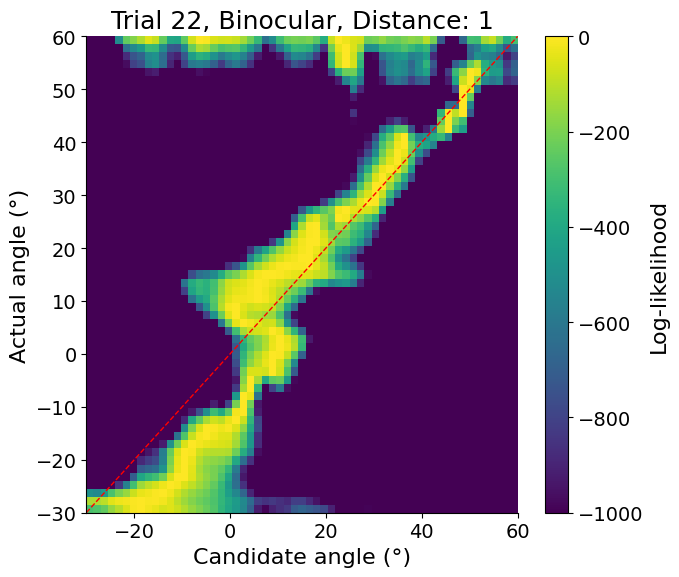

In [403]:
monocular_decoder.plot_likelihood_matrix(22)

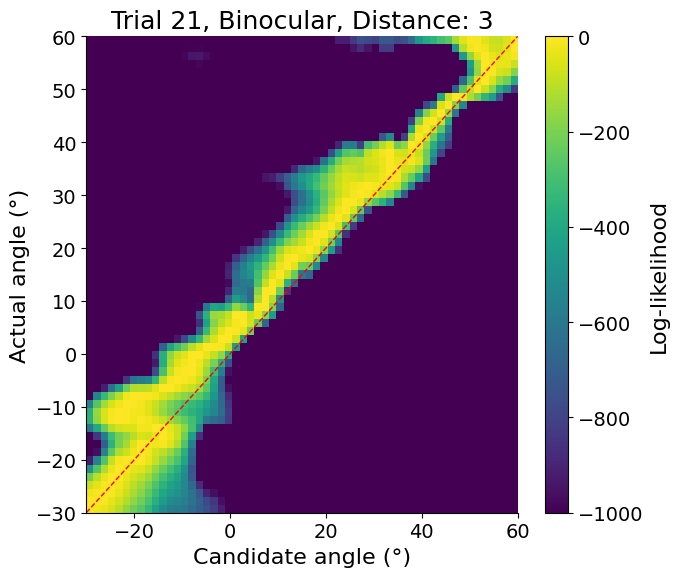

In [401]:
binocular_decoder.plot_likelihood_matrix(21)

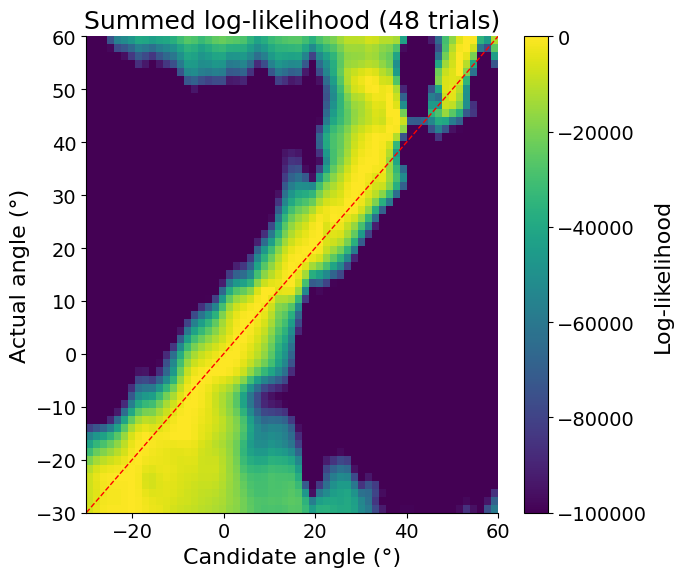

In [387]:
monocular_decoder.plot_likelihood_matrix_sum()

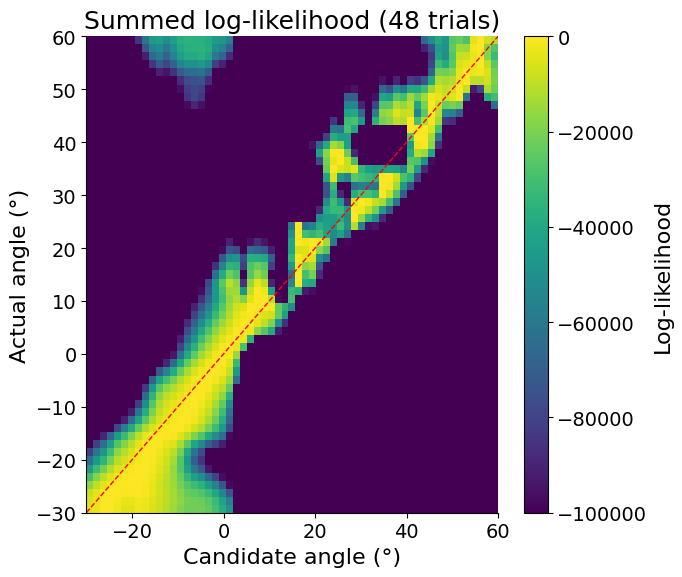

In [388]:
binocular_decoder.plot_likelihood_matrix_sum()

Using 128 cells
=== Fold 10/10 ===
Total predictions: 2928
Predictions per angle: 48
DISTANCE DECODER PERFORMANCE
  Mean Absolute Error:  0.982
  RMSE:                 1.128
  Bias:                 0.028
  Correlation:          0.115

  Reference (random guess MAE ~ 1.25)
=== Fold 10/10 ===
Total predictions: 2928
Predictions per angle: 48
DISTANCE DECODER PERFORMANCE
  Mean Absolute Error:  0.863
  RMSE:                 0.994
  Bias:                 -0.030
  Correlation:          0.470

  Reference (random guess MAE ~ 1.25)


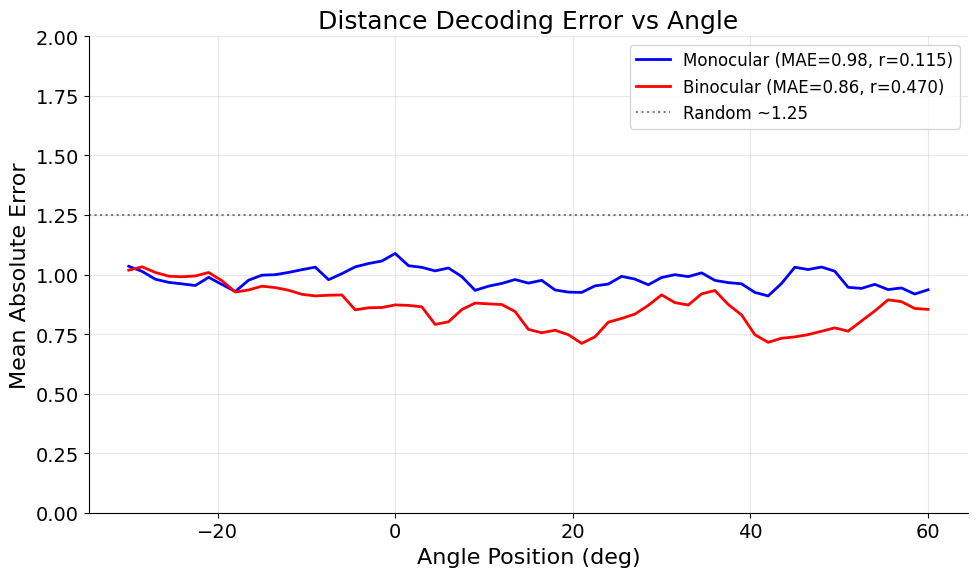

In [ ]:
cells_to_include = viz.filter_by_reliability(session_df, reliable_type='reliable', threshold=0.85)['cell_id'].values
print('Using {} cells'.format(len(cells_to_include)))


decoder_mono = MLEDistance(device, cells_to_include, monocular=1, chunk_size=1)
decoder_bino = MLEDistance(device, cells_to_include, monocular=0, chunk_size=1)

results_mono = decoder_mono.cross_validate()
results_bino = decoder_bino.cross_validate()

# either decoder instance works for plotting (they share angle_range)
fig = decoder_mono.plot_results_comparison(
    [results_mono, results_bino],
    ['Monocular', 'Binocular']
)

Repeat 100/100
Total predictions: 8400
Repeats: 100, Distances: 4
DISTANCE DECODER PERFORMANCE
  Mean Absolute Error:  0.844
  RMSE:                 0.952
  Bias:                 0.028
  Correlation:          0.670

  Reference (random guess MAE ~ 1.25)


(<Figure size 1000x600 with 1 Axes>,
 {'mae': np.float64(0.8441106352701674),
  'rmse': np.float64(0.9523575637390393),
  'bias': np.float64(0.027717243655804486),
  'std': np.float64(0.9519541394495236),
  'correlation': np.float64(0.6700169366970491)})

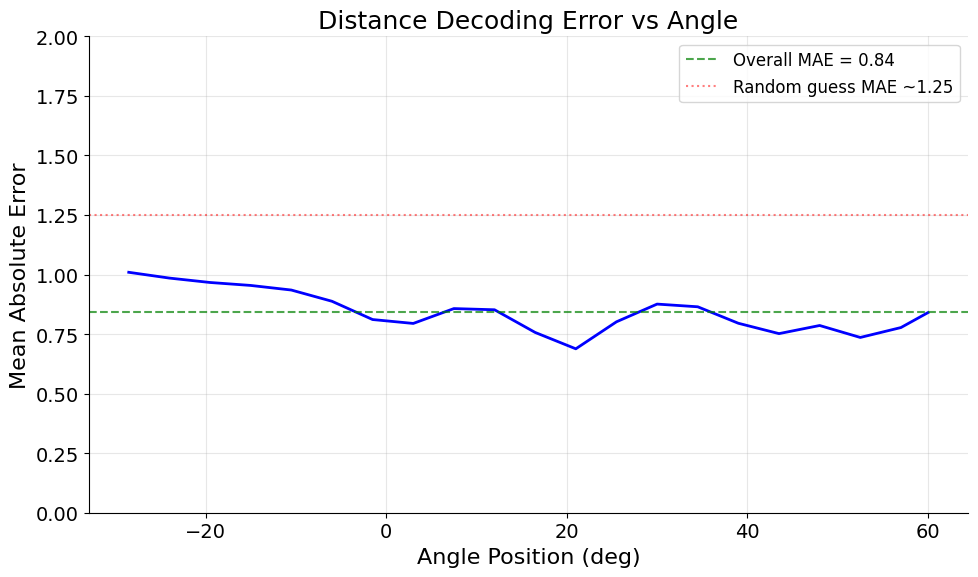

In [432]:
decoder = MLEDistance(device, cells_to_include, monocular=0, chunk_size=3)
results = decoder.cross_validate_mean(n_repeats=100)
decoder.plot_results(results)

Repeat 100/100
Total predictions: 8400
Repeats: 100, Distances: 4
DISTANCE DECODER PERFORMANCE
  Mean Absolute Error:  0.961
  RMSE:                 1.089
  Bias:                 -0.007
  Correlation:          0.248

  Reference (random guess MAE ~ 1.25)


(<Figure size 1000x600 with 1 Axes>,
 {'mae': np.float64(0.9613644641166493),
  'rmse': np.float64(1.0887587797648108),
  'bias': np.float64(-0.0068050200182774205),
  'std': np.float64(1.0887375130018764),
  'correlation': np.float64(0.24841032279691483)})

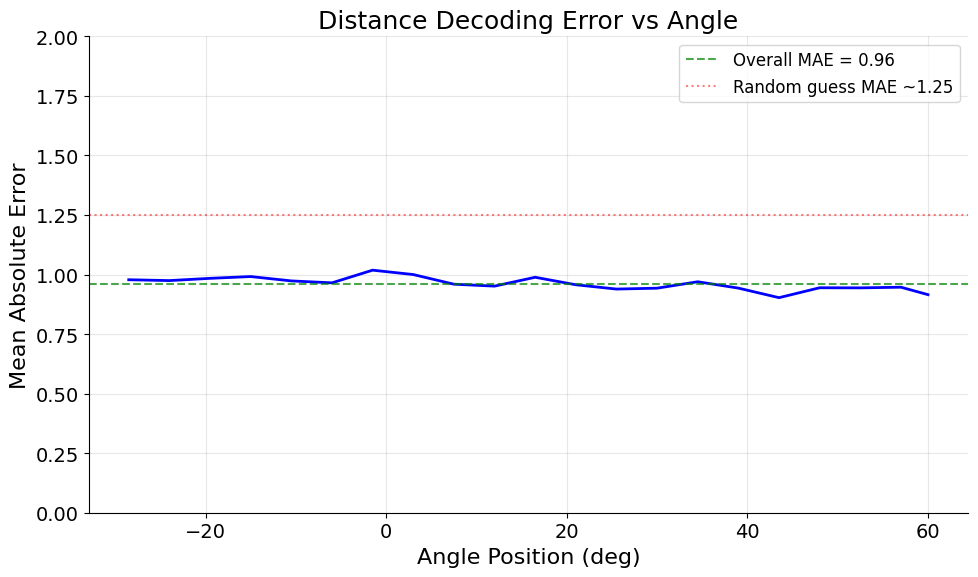

In [433]:
decoder = MLEDistance(device, cells_to_include, monocular=1, chunk_size=3)
results = decoder.cross_validate_mean(n_repeats=100)
decoder.plot_results(results)

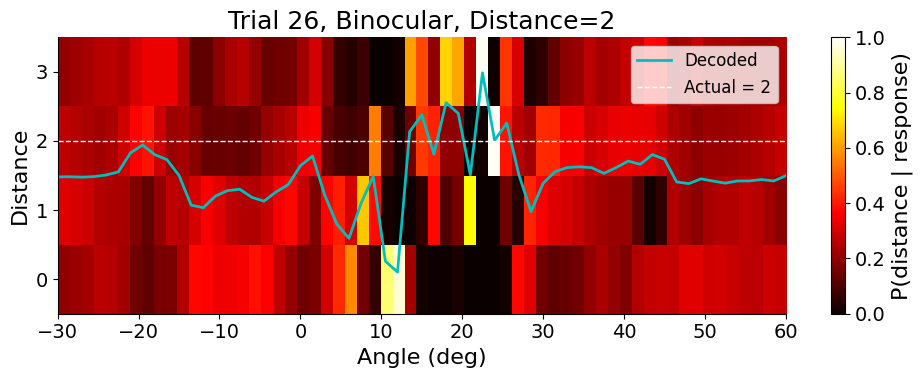

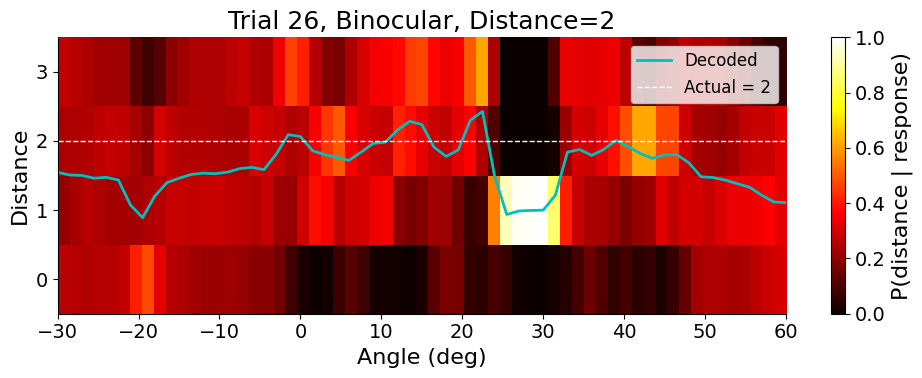

In [418]:
trial = 26
fig = decoder_mono.plot_trial_likelihood(trial)
fig = decoder_bino.plot_trial_likelihood(trial)

=== Fold 10/10 ===
Total predictions: 2928
Predictions per angle: 48
DISTANCE DECODER PERFORMANCE (Ridge)
  Mean Absolute Error:  0.958
  RMSE:                 1.094
  Bias:                 -0.016
  Correlation:          0.213

  Reference (random guess MAE ~ 1.25)


(<Figure size 1000x600 with 1 Axes>,
 {'mae': np.float64(0.9581663295870921),
  'rmse': np.float64(1.0938587580542047),
  'bias': np.float64(-0.01588812910142492),
  'std': np.float64(1.0937433656601279),
  'correlation': np.float64(0.21251941327053545)})

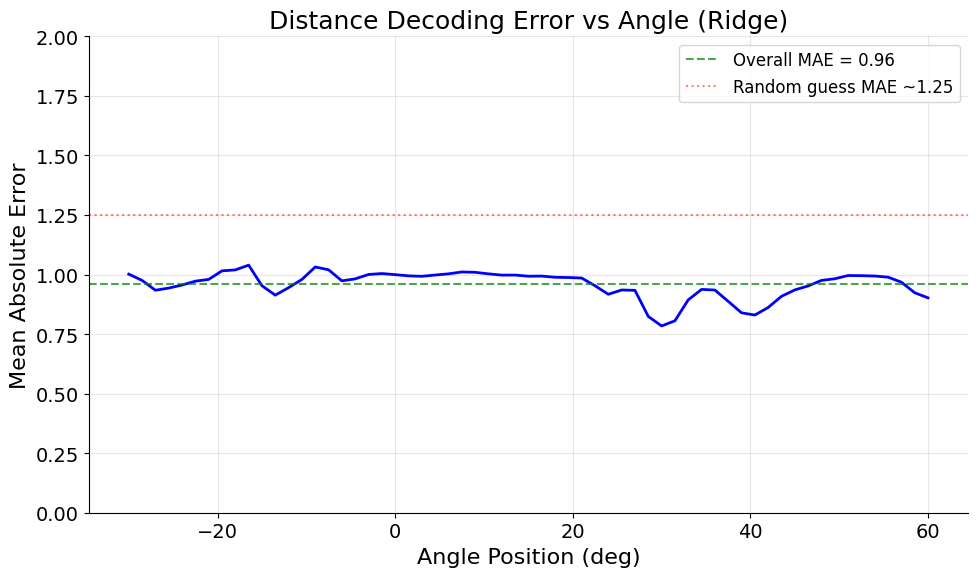

In [429]:
decoder = RidgeDistance(device, cells_to_include, monocular=1, chunk_size=1)
results = decoder.cross_validate(k_folds=10)
decoder.plot_results(results)

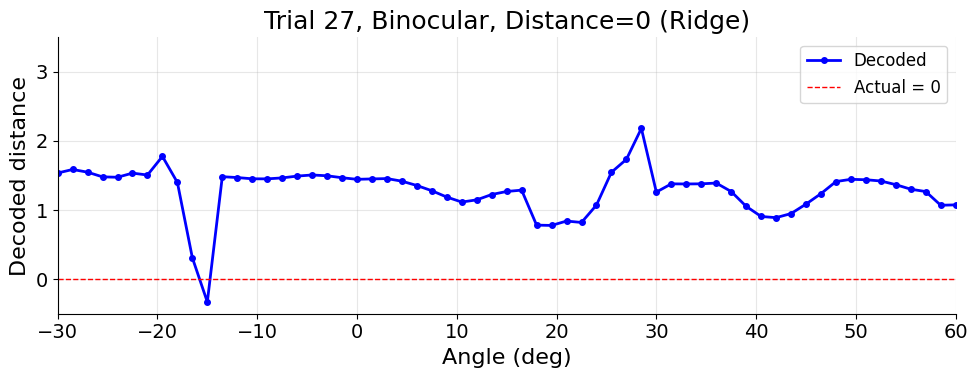

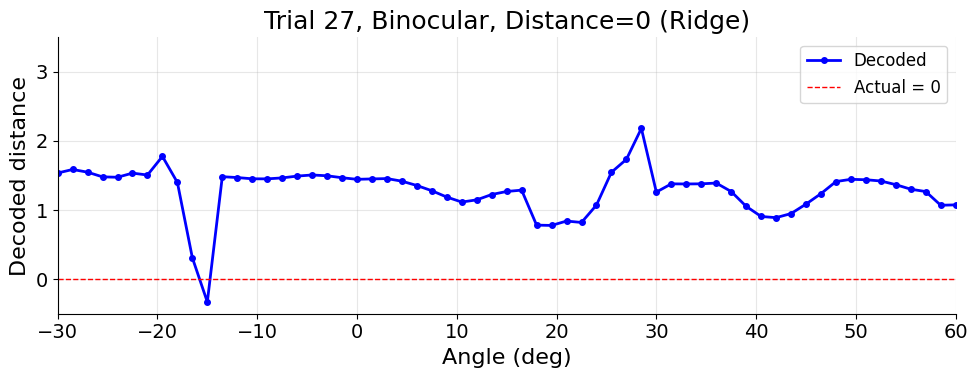

In [431]:
decoder.plot_trial(27)